sc-HistoMorphics: 
Integration of H&E-derived single-cell morphology with
Xenium in situ transcriptomics (breast cancer FFPE).

This script:
1. Segments nuclei from the H&E image using StarDist.
2. Computes CellProfiler-based morphology features.
3. Visualizes H&E channels and segmentation results.
4. Registers Xenium DAPI-based nuclei coordinates into H&E space.
5. Matches morphology nuclei to Xenium cells using spatial proximity.

Dataset:
https://www.10xgenomics.com/products/xenium-in-situ/preview-dataset-human-breast

Author: Elaheh Alizadeh

In [2]:
from tifffile import imread
import matplotlib.pyplot as plt
from utils import misc
import os
import numpy as np
import importlib
import seaborn as sns

This is utility function for Sc-HistoMorphics


2026-06-16 11:04:15.673562: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-06-16 11:04:15.722035: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-06-16 11:04:15.723126: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-06-16 11:04:17.825420: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [4]:
# you can download the H&E image from here:
he_url="https://cf.10xgenomics.com/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_he_image.tif"
# .tif is cropped version of .ome.tif image for H&E image.  use .ome.tiff
he_path=f"{in_dir}Xenium_FFPE_Human_Breast_Cancer_Rep1_he_image.ome.tif"

# Xenium output directory
# You can download it from here
#https://www.10xgenomics.com/products/xenium-in-situ/preview-dataset-human-breast
in_dir="/projects/activities/deepspace/data/spatial_transcriptome/Xenium/breastcancer/"


resDir="/projects/activities/deepspace/team/elaheh/results/Xenium/breast_cancer_sample1_rep1/2026_03/"
if_path=f"{in_dir}Xenium_FFPE_Human_Breast_Cancer_Rep1_if_image.ome.tif"
label_name=f"{resDir}_label.tif"

In [3]:
importlib.reload(misc);

This is utility function for Sc-HistoMorphics


In [7]:
%config Completer.use_jedi = False# tab shows function suggestions

# Script

In [5]:
%%time
# =============================================================================
# Image segmentation # takes about 5mins
# =============================================================================
img=imread(he_path)
labels=misc.segment_nuclei(img,label_name,prob_thresh=0.3,nms_thresh=0.1,force=False)

Segmentation mask exists. Loading from disk.
CPU times: user 7.43 s, sys: 3.38 s, total: 10.8 s
Wall time: 3.9 s


In [6]:
%%time
# =============================================================================
# Splitting channels and extracting morphology: takes about 5h
# =============================================================================
morph, hemo, eosin, cyto =  misc.compute_or_load_morphology(
        img, labels,in_dir,chunk_size=1500,force=False)

Loading existing CellProfiler measurements...
CPU times: user 5.8 s, sys: 3.04 s, total: 8.84 s
Wall time: 39.4 s


In [5]:
# =============================================================================
# Coordinate transformations
# =============================================================================
# --- Xenium data ---
nuc_center, nuc_bound, transform = misc.load_xenium_outputs(in_dir)
res_dapi = misc.get_tiff_resolution(if_path) # Xenium physical pixel size (µm)
nuc_center_hne = misc.transform_coords(nuc_center, "x_centroid", "y_centroid", transform, res_dapi)
nuc_bound_hne=misc.transform_coords(nuc_bound, "vertex_x", "vertex_y", transform, res_dapi)

In [12]:
np.max(nuc_bound_hne.groupby("cell_id").size()

<bound method NDFrame._add_numeric_operations.<locals>.max of cell_id
1         13
2         13
3         13
4         13
5         13
          ..
167776    13
167777    13
167778    13
167779    13
167780    13
Length: 167780, dtype: int64>

In [7]:
%%time
# =============================================================================
# Cell matching (morphology ↔ Xenium)
# =============================================================================
matched = misc.match_cells_parallel(
        morph, nuc_center_hne
    )

CPU times: user 1.62 s, sys: 706 ms, total: 2.33 s
Wall time: 8.04 s


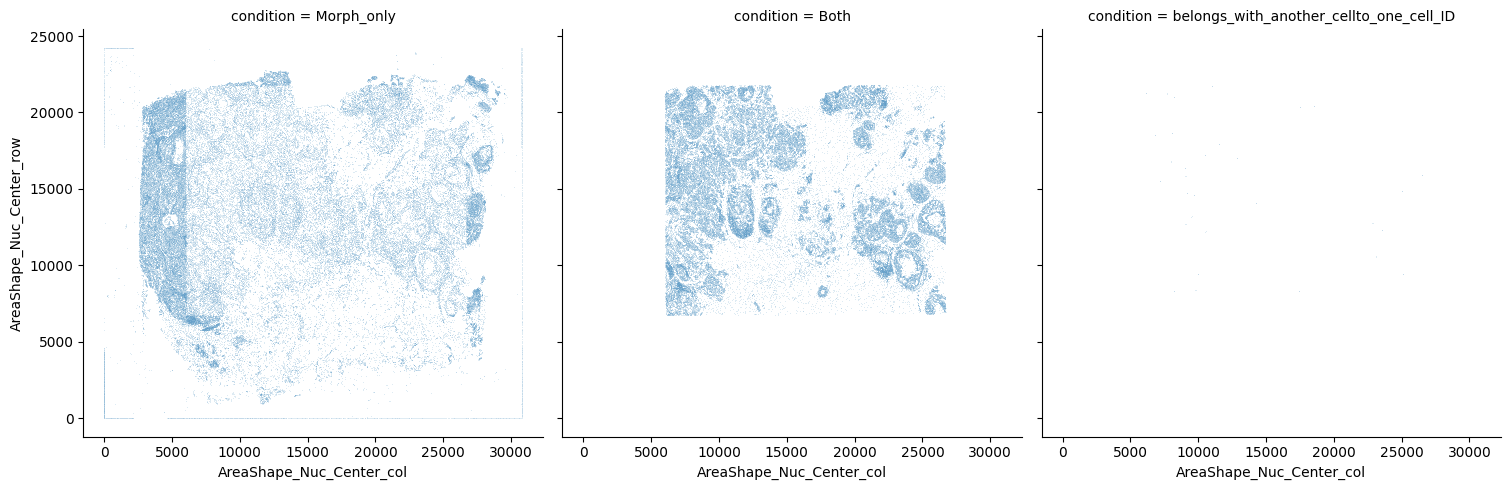

In [8]:
sns.relplot(
    data=matched,
    x="AreaShape_Nuc_Center_col",
    y="AreaShape_Nuc_Center_row",
    col="condition",
    kind="scatter",
    s=0.1,
    col_wrap=4   # adjust as needed
)

<Figure size 2500x1000 with 0 Axes>

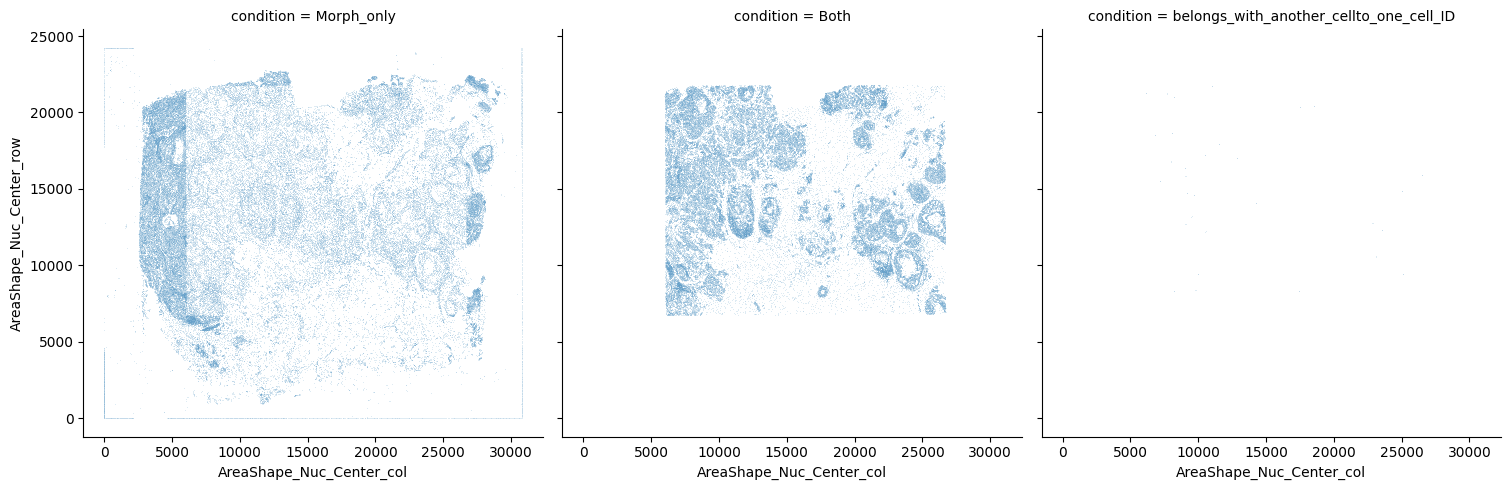

In [9]:
plt.figure(figsize=(25, 10))

sns.relplot(
    data=matched,
    x="AreaShape_Nuc_Center_col",
    y="AreaShape_Nuc_Center_row",
    col="condition",
    kind="scatter",
    s=0.1,
    col_wrap=4   # adjust as needed
)

# sns.scatterplot(
#         matched,
#         x="AreaShape_Nuc_Center_col",
#         y="AreaShape_Nuc_Center_row",
#         hue="condition",
#         s=10,
#     )
#plt.title("Morphology–Xenium Cell Matching")
plt.show()

In [11]:
matched.groupby("condition").size()

condition
Both                                        81803
Morph_only                                 100003
belongs_with_another_cellto_one_cell_ID        62
dtype: int64

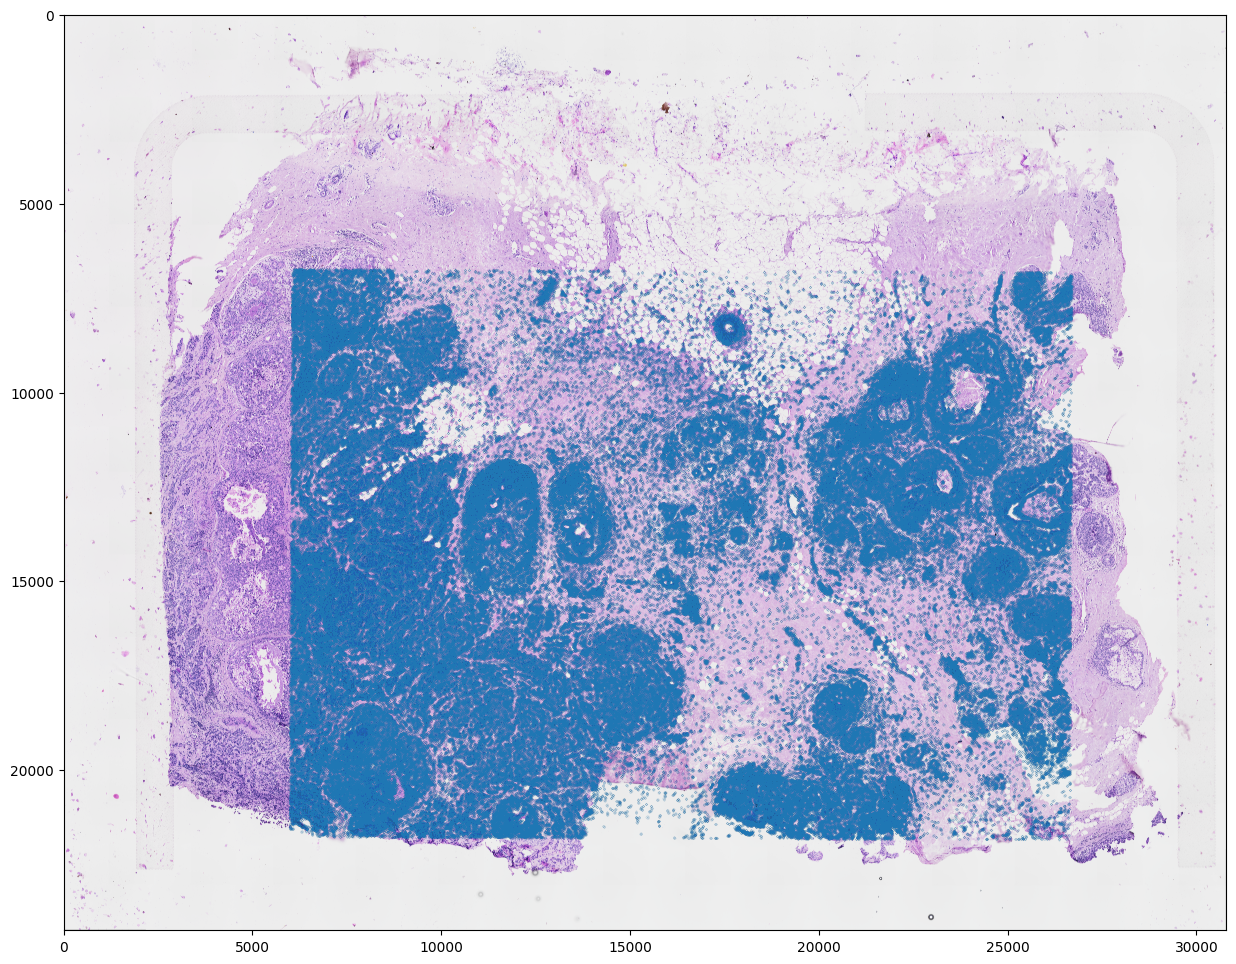

In [48]:
plt.figure(figsize=(15,15))
plt.imshow(img)
plt.scatter(nuc_bound_hne["vertex_x"],nuc_bound_hne["vertex_y"],s=0.001)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


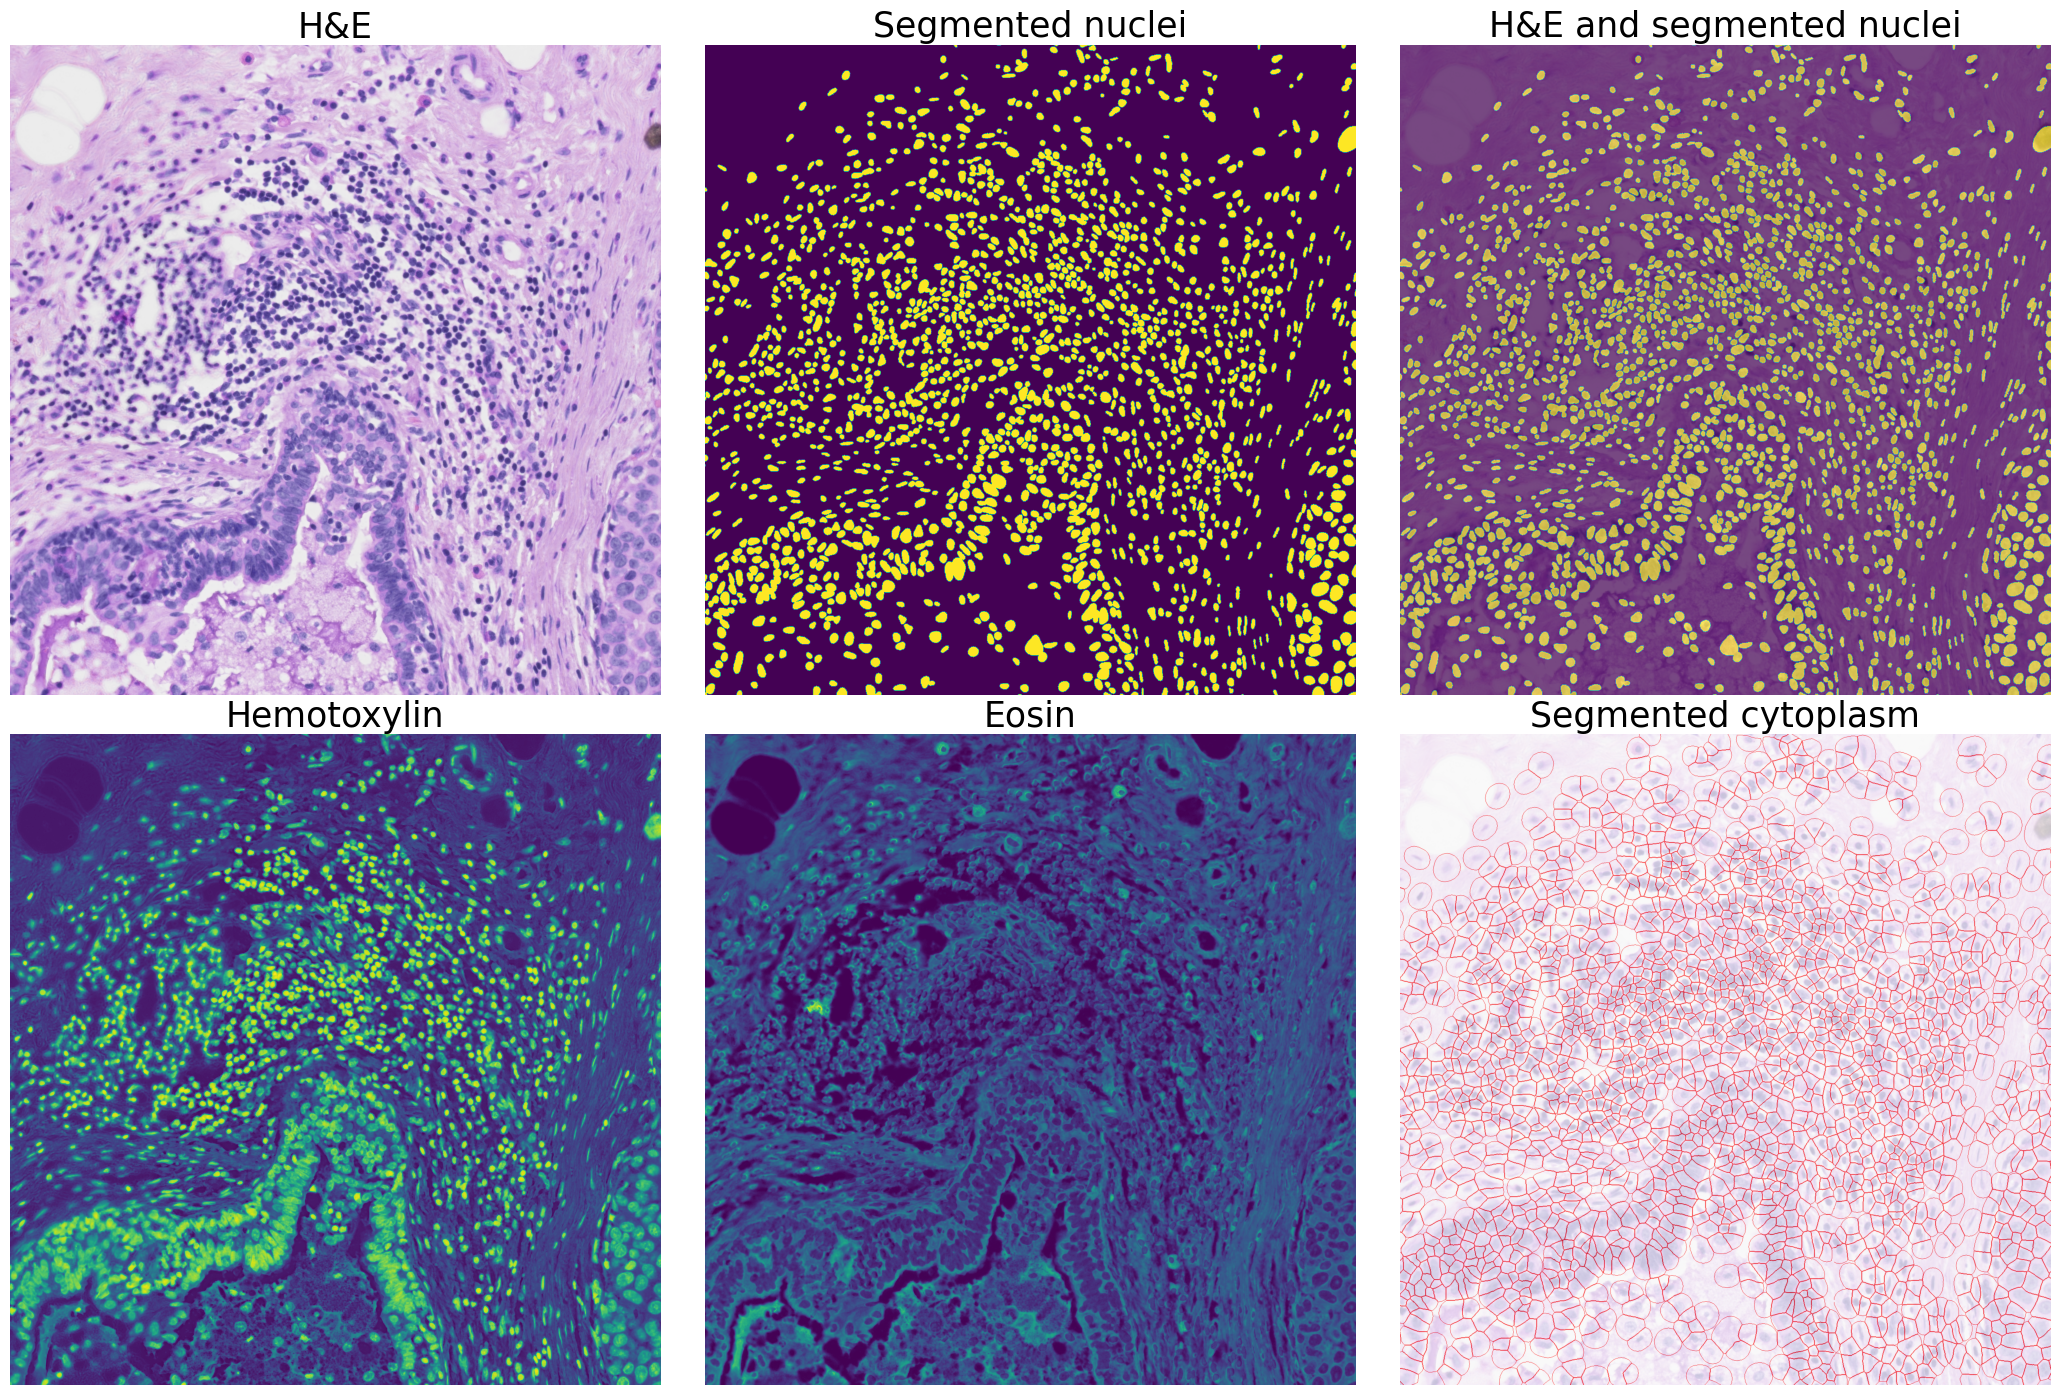

In [15]:
plt.figure(figsize=(21,14));
plt.subplot(2,3,1)
plt.imshow(img[9000:10500,21500:23000,:])
plt.axis("off")
plt.title("H&E",fontsize=25)


plt.subplot(2,3,2)
plt.imshow(labels[9000:10500,21500:23000]!=0)
plt.axis("off")
plt.title("Segmented nuclei",fontsize=25)

plt.subplot(2,3,3)
plt.imshow(img[9000:10500,21500:23000])
plt.imshow(labels[9000:10500,21500:23000]!=0,alpha=0.7)
plt.axis("off")
plt.title("H&E and segmented nuclei",fontsize=25)


plt.subplot(2,3,4)
plt.imshow(hemo[9000:10500,21500:23000])
plt.axis("off")
plt.title("Hemotoxylin",fontsize=25)


plt.subplot(2,3,5)
plt.imshow(eosin[9000:10500,21500:23000])
plt.axis("off")
plt.title("Eosin",fontsize=25)

plt.subplot(2,3,6)
plt.imshow(img[9000:10500,21500:23000])
plt.imshow(cyto[9000:10500,21500:23000],alpha=0.7)
plt.axis("off")
plt.title("Segmented cytoplasm",fontsize=25)

plt.tight_layout()

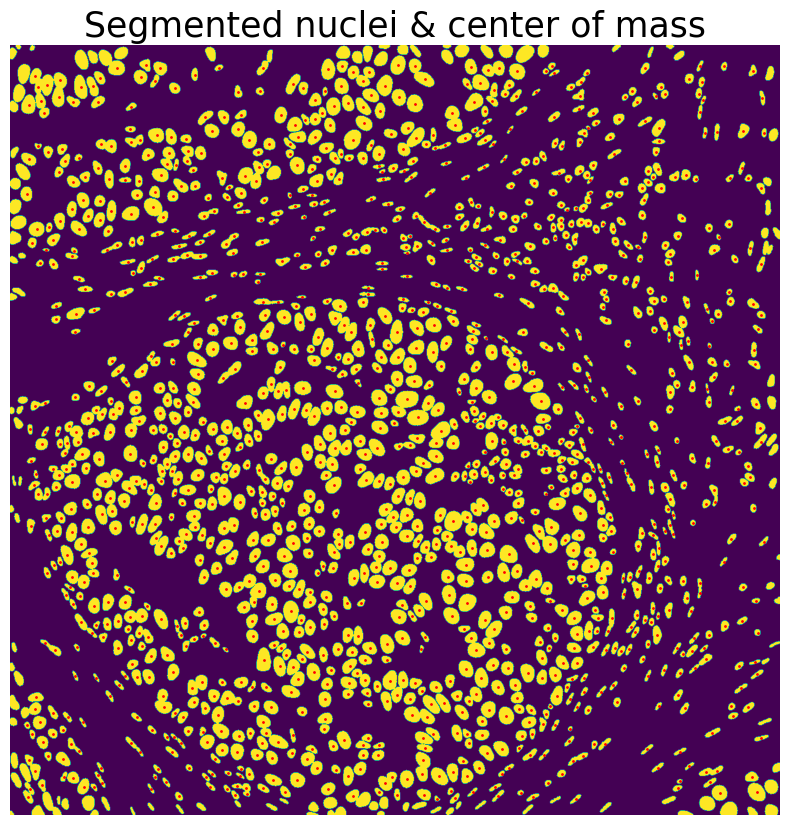

In [15]:
plt.figure(figsize=(10,10))
plt.imshow(labels!=0)

plt.axis("off")
plt.scatter(All2["AreaShape_Nuc_Center_col"],All2["AreaShape_Nuc_Center_row"],c="red",s=1)
plt.title("Segmented nuclei & center of mass",fontsize=25);